### **1. Setting Up**

In [24]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
from anndata import AnnData
import pathlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import skimage
import seaborn as sns
import tangram as tg
from sklearn.metrics import auc

sc.logging.print_header()
print(f"squidpy=={sq.__version__}")

%load_ext autoreload
%autoreload 2
%matplotlib inline

scanpy==1.9.8 anndata==0.9.2 umap==0.5.7 numpy==1.22.4 scipy==1.10.1 pandas==2.0.3 scikit-learn==1.3.2 statsmodels==0.14.1 igraph==0.11.8 pynndescent==0.5.13
squidpy==1.2.3
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### **2. Loading Datasets and Exploration**

##### **Datasets**
* **`adata_sc`** - single-cell/nucleus transcriptomic data (<span style="color:green">**173,199 cells x 19,957 genes**</span>)
* **`adata_sp`** - spatial transcriptomic data (<span style="color:green">**40,576 cells x 500 genes**</span>)
* <span style="color:green">**Objective** - Enrich the spatial transcriptomic data by predicting expression levels of the remaining 19,457 sc genes in the spatial data</span>

##### **Key Notation and Features**
* **`obs`** - Per-cell metadata
* **`var`** - Per-gene metadata
* **`uns`** - Unstructured data: UMAP params, colours and clustering settings
* **`obsm`** - Multi-dimensional cell info
* **`varm`** - Multi-dimensional gene info 
* **`obsp`** - Cell by cell matrices


##### **Single-Cell Sequencing Cell Metadata (`.obs`)**
1. **Biological labels and cell annotations**
- `class_name` - High-level cell type label (e.g. excitatory neuron, astrocyte)
- `subclass_name` - Intermediate-resolution label between class and supertype
- `supertype_name` - Finer subtype classification (most detailed)
- `class_label`, `subclass_label`, `supertype_label` - Numeric IDs corresponding to the above
- `celltype.full.score` - Confidence score for celltype.full

2. **Clustering and integration**
- `cluster_name`, `cluster_label`, `cluster_alias` - Cluster assignment
- `cluster_bootstrapping_probability` - Confidence in cluster assignment

3. **Quality control metrics**
- `nCount_RNA` - Total number of RNA molecules detected in cell
- `nFeature_RNA` - Number of unique genes expressed in cell
- `nCount_SCT`, `nFeature_SCT` - Same as above, but from Seurat's SCTransform
- `scDblFinder_score`, `scDblFinder_class`	Score indicating likelihood of being a doublet and doublet classification


4. **Sample and origin information**
- `Sample`, `Name`, `Sex`, `Line`, `DOB`, `DOD`, `age_days`, `age_months`

##### **Spatial Transcriptomics Cell Metadata (`.obs`)**
1. **Spatial coordinates and cell geometry**
- `center_x` - 2D spatial coordinate of the cell in tissue (x-axis)
- `center_y` - 2D spatial coordinate of the cell in tissue (y-axis)
- `volume` - Estimated cell volume (not z-depth)
- `min_x`, `min_y`, `max_x`, `max_y` - Bounding box coordinates per cell
- `anisotropy` - Shape elongation of the cell (e.g. round vs stretched)
- `perimeter_area_ratio` - Cell shape descriptor
- `solidity` - Compactness of the cell shape

2. **Biological labels and cell annotations**
- `class_name` - High-level cell type label (e.g. inhibitory neuron)
- `subclass_name` - Intermediate-resolution label between class and supertype
- `supertype_name` - Most detailed subtype classification
- `class_label`, `subclass_label`, `supertype_label` - Numeric IDs corresponding to the above
- `class_bootstrapping_probability`, `subclass_bootstrapping_probability`, `supertype_bootstrapping_probability` - Confidence in cell type labels

3. **Clustering and neighbourhood analysis**
- `cluster_name`, `cluster_label`, `cluster_alias` - Cluster assignment
- `cluster_bootstrapping_probability` - Confidence in cluster assignment
- `leiden` - Clustering assignment from the Leiden algorithm

4. **Gene and transcript metrics**
- `transcript_count` - Total number of RNA transcripts detected per cell
- `n_genes_by_counts` - Number of genes detected per cell
- `total_counts` - Sum of RNA counts across all genes
- `log1p_total_counts`, `log1p_n_genes_by_counts` - Log-normalised versions of total counts and gene counts

5. **Sample and region metadata**
- `EntityID` - Unique cell ID
- `fov` - Field of view ID (often used for spatial mapping in images)
- `Region` - Anatomical brain region label
- `dataset` - Dataset identifier, useful if multiple experiments were combined

6. **Imaging-based intensities**
- `DAPI_raw`, `p62_raw`, `PolyT_raw`, `Ctsd_raw`, `gH2Ax_raw` - Raw intensities from various imaging channels
- `DAPI_high_pass`, `p62_high_pass`, `PolyT_high_pass`, `Ctsd_high_pass`, `gH2Ax_high_pass` - High-pass filtered versions to highlight finer structures

7. **Colours for plotting**
- `class_color`, `subclass_color` - Precomputed colours for each cell type class (used in visualisation tools)

##### **Spatial Transcriptomics Gene Metadata (`.var`)**
1. **Gene detection and abundance**
- `n_cells_by_counts` - Number of cells in which each gene is detected (non-zero expression)
- `mean_counts` - Mean expression level of each gene across all cells
- `log1p_mean_counts` - Log-transformed version of mean expression for each gene

2. **Dropout and expression metrics**
- `pct_dropout_by_counts` - Percentage of cells where each gene was not detected (dropout rate)
- `total_counts` - Total counts for each gene across all cells
- `log1p_total_counts` - Log-transformed total counts (helps reduce skew)

3. **Normalised expression summary**
- `mean` - Mean of the normalised or scaled expression values
- `std` - Standard deviation of the normalised or scaled expression values


In [2]:
adata_sc = sc.read('gene_data/ageing_rna_20250114.h5ad')
print(adata_sc)

adata_st = sc.read('gene_data/ag02reg00_rawcounts.h5ad')
print(adata_st)

AnnData object with n_obs × n_vars = 173199 × 19957
    obs: 'id_barcode', 'scDblFinder_score', 'scDblFinder_class', 'celltype', 'sample', 'barcode', 'id_barcode.1', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'leverage.score', 'sketch_snn_res.2', 'seurat_clusters', 'celltype.full', 'celltype.full.score', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'Name', 'Sex', 'Line', 'DOB', 'DOD', 'age_days', 'age_months', 'Sample #'
    var: 'Unnamed: 0'
AnnData object with n_obs × n_vars = 40576 × 500
    obs: 'EntityID', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'cell_id', 'class_la

### **3. Data Pre-Processing and Training Gene Selection**

1. **Normalise** gene data raw counts across both datasets

2. Genes **scored** by how well they differentiate cell classes - each gene gets a score for each of the 33 classes using t-test - <span style="color:orange">`rank_gene_groups`</span>

    * t-test assumes normality in gene distributions, is  <span style="color:red">**Wilcoxon**</span> better suited here

    * Removes class with only one cell before this is done - <span style="color:red">**15 HY Gnrh1 Glut**</span>

3. 100 genes that most differentiate groups selected then unique genes from this are stored in <span style="color:purple">**markers**</span>

4. These **1169** marker genes are used as **training genes**, this is further processed using `pp_adatas`, which does the following:

    * Takes a list of genes from user via the `genes` argument. These genes are used as training genes (<span style="color:green">**1169**</span>).

    * Annotates training genes under the `training_genes` field, in `uns` dictionary, of each AnnData. 

    * Ensure consistent gene order in the datasets (_Tangram_ requires that the the $j$-th column in each matrix correspond to the same gene).

    * If the counts for a gene are **all zeros** in one of the datasets, the gene is **removed** from the training genes.

    * If a gene is not present in both datasets, the **gene is removed** from the training genes.

    * In the pp_adatas function, the gene names are converted to lower case to get rid of the inconsistent capitalization. If this is not wanted, you can set the parameter gene_to_lowercase = False 

    * <span style="color:red">**Can try varying the genes used in training, can try using all overlap genes instead of the top 100 differentiating genes**</span>

* **Overall, there are <span style="color:green">464 shared genes</span> between the single cell and spatial datasets, but only <span style="color:green">148</span> of these are marker genes**

In [3]:
# Normalise the single-cell data (because different cells are sequenced at different depths)
sc.pp.normalize_total(adata_sc, target_sum=1e4)
sc.pp.log1p(adata_sc)

# Normalise the spatial data (because different cells are sequenced at different depths)
sc.pp.normalize_total(adata_st, target_sum=1e4)
sc.pp.log1p(adata_st)

# Removes the groups 15 HY Gnrh1 Glut because it contains 
# only one sample
# This means statistics cannot be performed on this group
adata_sc = adata_sc[adata_sc.obs['class_name'] != "15 HY Gnrh1 Glut"]

In [4]:
sc.tl.rank_genes_groups(adata_sc, groupby="class_name", use_raw=False)

In [5]:
# Filters for the 100 most differentially expressed genes for each group then selects unique genes
markers_df = pd.DataFrame(adata_sc.uns["rank_genes_groups"]["names"]).iloc[0:100, :]    # Selects top 100 genes differentiating each group
markers = list(np.unique(markers_df.melt().value.values))   # Selects unique genes after converting wide table to long table
len(markers)

1169

In [7]:
tg.pp_adatas(adata_sc, adata_st, genes=markers)

INFO:root:148 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:464 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.


### **4. Find alignment and Save Mapping Matrix**

To find the optimal spatial alignment for scRNA-seq profiles, we use the `map_cells_to_space` function:
- The function maps iteratively as specified by `num_epochs`. We typically interrupt mapping  after the score plateaus. 
- The score measures the <span style="color:green">**similarity**</span> between the gene expression of the mapped cells vs spatial data on the training genes.
- The default mapping mode is `mode='cells'`, which is recommended to run on a GPU - <span style="color:red">**this is what I need to do**</span>
- Alternatively, one can specify `mode='clusters'` which averages the single cells belonging to the same cluster (pass annotations via  `cluster_label`). This is faster, and is our chioce when scRNAseq and spatial data come from different specimens.
- If you wish to run Tangram with a GPU, set `device=cuda:0` otherwise use the set `device=cpu`. 
- `density_prior` specifies the cell density within each spatial voxel. Use `uniform` if the spatial voxels are at single cell resolution (_ie_ MERFISH). The default value, `rna_count_based`, assumes that cell density is proportional to the number of RNA molecules.

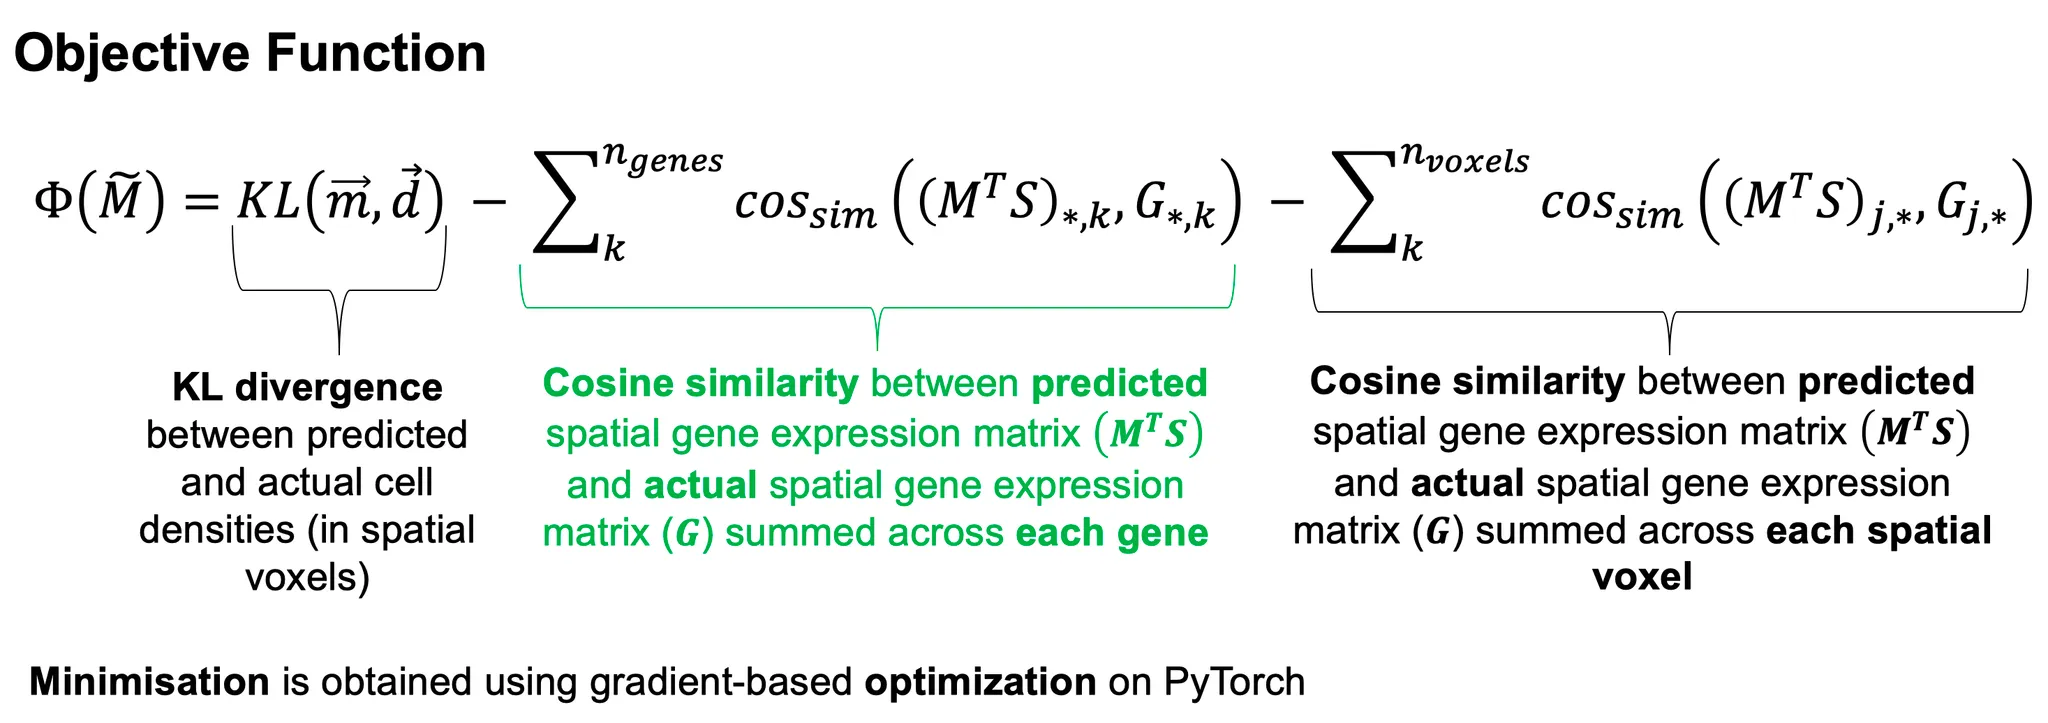

In [8]:
ad_map = tg.map_cells_to_space(adata_sc, adata_st,
    # mode="cells",
    mode="clusters",
    cluster_label='class_name',  # .obs field w cell types
    density_prior='uniform',
    num_epochs=500,
    # device="cuda:0",
    device='cpu',
)


## When I can run the code on a GPU
# ad_map = tg.map_cells_to_space(adata_sc, adata_st,
#     mode="cells",
#     # mode="clusters",
#     # cluster_label='class_name',  # .obs field w cell types
#     density_prior='uniform',
#     num_epochs=500,
#     # device="cuda:0",
#     device='cpu',
# )

INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 148 genes and uniform density_prior in clusters mode...
INFO:root:Printing scores every 100 epochs.


Score: 0.368, KL reg: 0.105
Score: 0.576, KL reg: 0.004
Score: 0.577, KL reg: 0.004
Score: 0.578, KL reg: 0.004
Score: 0.578, KL reg: 0.004


INFO:root:Saving results..


**Save the mapping matrix**
- The mapping results are stored in the returned `AnnData` structure, saved as `ad_map`, structured as following:
- The cell-by-spot matrix `X` contains the probability of cell/cluster `i` to be in spot `j`. 
- The `obs` dataframe contains the metadata of the single cells. We use the single cell clusters, so there is only 33 here. 
- The `var` dataframe contains the metadata of the spatial data.
- The `uns` dictionary contains a dataframe with various information about the training genes (saved as `train_genes_df`).

In [9]:
ad_map.write("mapped.h5ad")

### **5. Cell-Type Maps**
- <span style="color:red">**Incomplete because I used the clusters method, need cells for better gene prediction**</span> 

In [29]:
ad_map

AnnData object with n_obs × n_vars = 33 × 40576
    obs: 'class_name', 'cluster_density'
    var: 'EntityID', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability', 'uniform_density', 'rna_count_based_density'
    uns: 'train_genes_df', 'training_history'

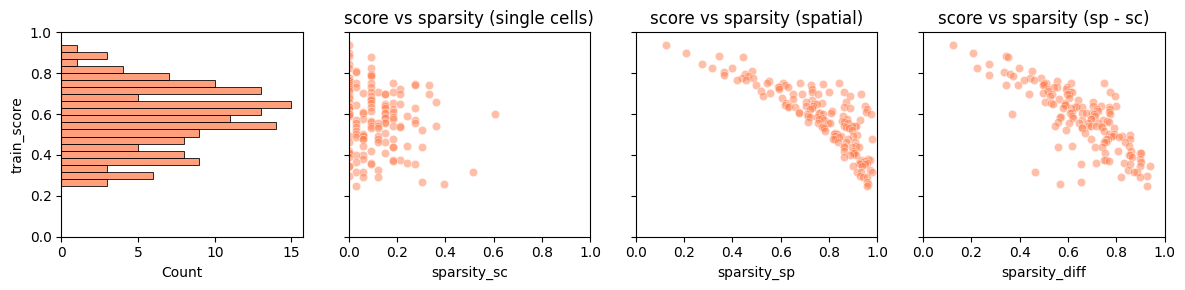

In [10]:
tg.plot_training_scores(ad_map, bins=20, alpha=.5)

- The first panel is a histogram of the simlarity scores for each training gene.
- In the second panel, each dot is a training gene and we can observe the training score (y-axis) and the sparsity in the scRNA-seq data (x-axis) of each gene. 
- The third panel is similar to the second one, but contains the gene sparsity of the spatial data. Spatial data are usually more sparse than single cell data, a discrepancy which is often responsible for low quality mapping.
- In the last panel, we show the training scores as a function of the difference in sparsity between the dataset. For genes with comparable sparsity, the mapped gene expression is very similar to that in the spatial data. However, if a gene is quite sparse in one dataset (typically, the spatial data) but not in other, the mapping score is lower. This occurs as Tangram cannot properly matched the gene pattern because of inconsistent amount of dropouts between the datasets.

In [11]:
ad_map.uns['train_genes_df']

,train_score,sparsity_sc,sparsity_sp,sparsity_diff
cadm1,0.938238,0.000000,0.124359,0.124359
pcdh9,0.898300,0.000000,0.206674,0.206674
grin2a,0.882498,0.000000,0.342937,0.342937
chrm1,0.878222,0.090909,0.441566,0.350657
grm3,0.845996,0.000000,0.274522,0.274522
...,...,...,...,...
chn2,0.290996,0.121212,0.940334,0.819122
tmem163,0.290017,0.060606,0.957610,0.897004
vmn2r1,0.264924,0.303030,0.958276,0.655246
thbs2,0.255402,0.393939,0.961480,0.567540


### New Spatial Data via Aligned Single Cells

If the mapping mode is `'cells'`, we can now generate the "new spatial data" using the mapped single cell: this is done via `project_genes`. The function accepts as input a mapping (`adata_map`) and corresponding single cell data (`adata_sc`). The result is a voxel-by-gene `AnnData`, formally similar to `adata_st`, but containing gene expression from the mapped single cell data rather than Visium. For downstream analysis, we always replace `adata_st` with the corresponding `ad_ge`.

In [16]:
ad_ge = tg.project_genes(adata_map=ad_map, adata_sc=adata_sc, cluster_label='class_name')

ad_ge

AnnData object with n_obs × n_vars = 40576 × 19957
    obs: 'EntityID', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability', 'uniform_density', 'rna_count_based_density'
    var: 'Unnamed: 0', 'n_cells', 'is_training'
    uns: 'log1p', 'rank_genes_groups', 'training_genes', 'overlap_genes'

Let's choose a few training genes mapped with low score, to try to understand why.

In [79]:
genes = ['cadm1', 'chn2', 'grin2a']
ad_map.uns['train_genes_df']

,train_score,sparsity_sc,sparsity_sp,sparsity_diff
cadm1,0.938238,0.000000,0.124359,0.124359
pcdh9,0.898300,0.000000,0.206674,0.206674
grin2a,0.882498,0.000000,0.342937,0.342937
chrm1,0.878222,0.090909,0.441566,0.350657
grm3,0.845996,0.000000,0.274522,0.274522
...,...,...,...,...
chn2,0.290996,0.121212,0.940334,0.819122
tmem163,0.290017,0.060606,0.957610,0.897004
vmn2r1,0.264924,0.303030,0.958276,0.655246
thbs2,0.255402,0.393939,0.961480,0.567540


To visualize gene patterns, we use the helper `plot_genes`. This function accepts two voxel-by-gene `AnnData`: the actual spatial data  (`adata_measured`), and a Tangram spatial prediction (`adata_predicted`). The function returns gene expression maps from the two spatial `AnnData` on the genes `genes`.

# Plot Gene Expression

In [17]:
df_all_genes = tg.compare_spatial_geneexp(ad_ge, adata_st, adata_sc)
df_all_genes

,score,is_training,sparsity_sp,sparsity_sc,sparsity_diff
aldoc,0.945255,False,0.035193,0.848820,-0.813627
cadm1,0.938238,True,0.124359,0.124170,0.000189
chst1,0.926826,False,0.168720,0.814957,-0.646237
elmod1,0.898869,False,0.259538,0.592541,-0.333004
pcdh9,0.898300,True,0.206674,0.021143,0.185530
...,...,...,...,...,...
gal,0.086780,False,0.988786,0.999099,-0.010313
igfbpl1,0.084377,False,0.967666,0.996466,-0.028801
sln,0.080176,False,0.969908,0.998707,-0.028798
calcr,0.072274,False,0.984720,0.999088,-0.014368


In [18]:
df_all_genes.to_csv("all_genes_comparison.csv", index=False)

In [19]:
import pandas as pd

df_all_genes = pd.read_csv('all_genes_comparison.csv')


In [25]:
def eval_metric(df_all_genes, test_genes=None):
    """
    Compute metrics on given test_genes set for evaluation
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:      
        dict with values of each evaluation metric ("avg_test_score", "avg_train_score", "auc_score"), 
        tuple of auc fitted coordinates and raw coordinates(test_score vs. sparsity_sp coordinates)
    """

    # validate test_genes:
    if test_genes is not None:
        if not set(test_genes).issubset(set(df_all_genes.index.values)):
            raise ValueError(
                "the input of test_genes should be subset of genes of input dataframe"
            )
        test_genes = np.unique(test_genes)

    else:
        test_genes = list(
            set(df_all_genes[df_all_genes["is_training"] == False].index.values)
        )

    # calculate:
    test_gene_scores = df_all_genes.loc[test_genes]["score"]
    test_gene_sparsity_sp = df_all_genes.loc[test_genes]["sparsity_sp"]
    test_score_avg = test_gene_scores.mean()
    train_score_avg = df_all_genes[df_all_genes["is_training"] == True]["score"].mean()

    # sp sparsity weighted score
    test_score_sps_sp_g2 = np.sum(
        (test_gene_scores * (1 - test_gene_sparsity_sp))
        / (1 - test_gene_sparsity_sp).sum()
    )

    # tm metric
    # Fit polynomial'
    xs = list(test_gene_scores)
    ys = list(test_gene_sparsity_sp)
    pol_deg = 2
    pol_cs = np.polyfit(xs, ys, pol_deg)  # polynomial coefficients
    pol_xs = np.linspace(0, 1, 10)  # x linearly spaced
    pol = np.poly1d(pol_cs)  # build polynomial as function
    pol_ys = [pol(x) for x in pol_xs]  # compute polys
    
    if pol_ys[0] > 1:
        pol_ys[0] = 1

    # if real root when y = 0, add point (x, 0):
    roots = pol.r
    root = None
    for i in range(len(roots)):
        if np.isreal(roots[i]) and roots[i] <= 1 and roots[i] >= 0:
            root = roots[i]
            break

    if root is not None:
        pol_xs = np.append(pol_xs, root)
        pol_ys = np.append(pol_ys, 0)       
        
    np.append(pol_xs, 1)
    np.append(pol_ys, pol(1))

    # remove point that are out of [0,1]
    del_idx = []
    for i in range(len(pol_xs)):
        if pol_xs[i] < 0 or pol_ys[i] < 0 or pol_xs[i] > 1 or pol_ys[i] > 1:
            del_idx.append(i)

    pol_xs = [x for x in pol_xs if list(pol_xs).index(x) not in del_idx]
    pol_ys = [y for y in pol_ys if list(pol_ys).index(y) not in del_idx]

    # Compute are under the curve of polynomial
    auc_test_score = np.real(auc(pol_xs, pol_ys))

    metric_dict = {
        "avg_test_score": test_score_avg,
        "avg_train_score": train_score_avg,
        "sp_sparsity_score": test_score_sps_sp_g2,
        "auc_score": auc_test_score,
    }

    auc_coordinates = ((pol_xs, pol_ys), (xs, ys))

    return metric_dict, auc_coordinates


In [38]:
def plot_auc(df_all_genes, test_genes=None):
    """
        Plots auc curve which is used to evaluate model performance.
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:
        None
    """
    metric_dict, ((pol_xs, pol_ys), (xs, ys)) = eval_metric(df_all_genes, test_genes)
    
    fig = plt.figure()
    plt.figure(figsize=(6, 5))

    plt.plot(pol_xs, pol_ys, c='r')
    sns.scatterplot(x=xs, y=ys, alpha=0.5, edgecolors='face')
        
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.gca().set_aspect(.5)
    plt.xlabel('score')
    plt.ylabel('spatial sparsity')
    plt.tick_params(axis='both', labelsize=8)
    plt.title('Prediction on test transcriptome')
    
    textstr = 'auc_score={}'.format(np.round(metric_dict['auc_score'], 3))
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.3)
    # place a text box in upper left in axes coords
    plt.text(0.03, 0.1, textstr, fontsize=11, verticalalignment='top', bbox=props);


<Figure size 640x480 with 0 Axes>

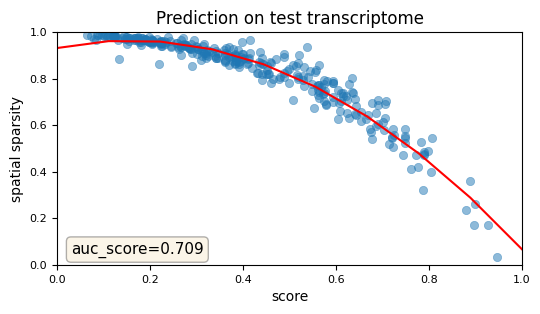

In [39]:
plot_auc(df_all_genes)

6. **Cross-Validation Approach**

In [ ]:
cv_dict, ad_ge_cv, df = tg.cross_val(adata_sc, 
                                     adata_st, 
                                    #  device='cuda:0', 
                                     device='cpu', 
                                     mode='clusters',
                                     cv_mode='loo',
                                     num_epochs=300,
                                     cluster_label='class_name',
                                     return_gene_pred=True,
                                     verbose=False,
                                     )

  1%|          | 1/148 [01:46<4:20:28, 106.32s/it]


KeyboardInterrupt: 

In [ ]:
tg.plot_test_scores(df, bins=10, alpha=.7)